<img src="../assets/Logo_de_la_Facultad_Experimental_de_Ciencia_y_Tecnología.svg" alt="Facultad Experimental de Ciencia y Tecnologia" width="140">

# Universidad de Carabobo
### Facultad Experimental de Ciencia y Tecnologia (FACYT) — Departamento de Computacion
### Elective: Aprendizaje Automatico — Project Assignment 3 (Model Selection and Hyperparameter Optimization)

**Students:** *Andrés Gubaira & Jhosber Ynojosa*
**Date:** November 2026

---

# Modeling and Model Selection — Rick and Morty Speaker Prediction

**Purpose.** Notebooks 01 (EDA) and 02 (data preparation) defined the problem, the train/test split and a
leakage-safe preparation pipeline. This notebook answers the question that remains: **which complete pipeline
(preparation plus model) generalizes best to lines it has never seen, and why is that choice defensible?**

```text
Metric and protocol fixed before any result
    ↓
Same split and preparation as notebook 02, verified against its files
    ↓
Cross-validation grouped by episode, identical folds for every model
    ↓
Naive baseline + three candidate models
    ↓
Comparison of the six feature variants of notebook 02
    ↓
Optuna on the two most promising candidates
    ↓
Selection with cross-validation only
    ↓
One single evaluation on test
```

> **Test-set limitation.** The EDA inspected the complete labelled dataset before the split existed, so the test
> partition is a held-out set for the course workflow, not a perfectly untouched final test. In this notebook test
> is used exactly once, in Section 11, after every decision has been closed.

## 1. Objective, Metric and Evaluation Protocol

| Element | Decision |
|---|---|
| **Type of problem** | Multiclass classification: each line belongs to exactly one of five speakers (Rick, Morty, Jerry, Beth, Summer). |
| **Primary metric** | **Macro-F1.** F1 is computed for each speaker (the balance between precision, "when the model says Morty, how often is it Morty", and recall, "of Morty's lines, how many does it find") and the five values are averaged with equal weight. |
| **Real error it represents** | A speaker the model ignores or over-predicts. Each character weighs one fifth of the score, so a model that always answers Rick (35.9% of the training lines) scores only about 0.11, even though its accuracy is about 36%. This matches the project goal of recognizing every character's voice, not only the most talkative one. |
| **Secondary metrics** | Accuracy (to compare with the 35.9% majority baseline of notebook 02), balanced accuracy (mean recall per speaker), per-speaker precision and recall, and the confusion matrix. |
| **How macro-F1 is averaged** | Unweighted mean over the five classes (`average="macro"`), computed separately on each validation fold. |
| **Data split** | The episode-grouped train/test split of notebook 02: test (8 episodes) is reserved; everything else uses train only. |
| **Validation** | Cross-validation on train with folds grouped by episode (Section 4); the same folds for every model and every Optuna trial. |

The metric and the protocol are fixed here, before any model is trained, so that they cannot be chosen to favour a
particular result.

## 2. Imports and Configuration

All dependencies come from `requirements.txt` (Optuna is new in this stage), which pins the exact versions used to
run the notebooks: the episodes drawn for the test set depend on the version of scikit-learn, so another version
could produce a different split, and Section 3 would stop with an error instead of continuing with it. The budget of the search (trials and
time limit) is declared here so it is visible before any result. Cross-validation runs sequentially (`N_JOBS = 1`):
it is slower, but every run is deterministic and free of side effects from parallel worker processes.

In [1]:
import hashlib
import json
import platform
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_val_predict, cross_validate
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, MinMaxScaler, StandardScaler
from sklearn.svm import LinearSVC

N_FOLDS = 5
N_OPTUNA_TRIALS = 40
OPTUNA_TIMEOUT_SECONDS = 900  # per study; whichever limit is reached first stops it
N_MODELS_TO_TUNE = 2
N_JOBS = 1  # sequential: deterministic and free of process-pool side effects

SCORING = {
    "macro_f1": "f1_macro",
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
}
PRIMARY_METRIC = "macro_f1"

# Allow execution from the project root or from notebooks/.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "Rick-n-Morty.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "Rick-n-Morty.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. Run this notebook from the repository root or from notebooks/."
    )
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"  # split manifest and metadata written by notebook 02

# One line per study instead of one line per trial; this is Optuna's own log level, not a warning filter.
optuna.logging.set_verbosity(optuna.logging.WARNING)

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 140)

print(f"Python: {platform.python_version()}")
print(f"pandas: {pd.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"Optuna: {optuna.__version__}")

Python: 3.14.9
pandas: 3.0.2
scikit-learn: 1.9.0
Optuna: 5.0.0


## 3. Recovering the Preparation of Notebook 02

**Motivation.** Model selection compares complete pipelines, so this notebook must start from exactly the same data,
split, target and preparation as notebook 02. The definitions below are copied verbatim from notebook 02 (its inspection tables and prints are left out): the
constants, the schema validation, the label normalization, the spoken-text cleaning and row filters, the
episode-grouped split, the target definition learned on train, the six feature variants and the preparation
pipeline. Nothing is fitted here; every step that learns from data is fitted later, inside each fold.

In [2]:
RANDOM_STATE = 42
TEST_EPISODE_SHARE = 0.20  # share of episodes drawn at random for the test set
N_TOP_SPEAKERS = 5
ID_COLUMN = "line_id"
GROUP_COLUMN = "episode no."
TEXT_COLUMN = "dialogue"
TARGET_COLUMN = "speaker"
EPISODE_RANGE = (1, 51)  # episode numbers documented by the source transcripts (EDA, Section 3.1)
MAIN_FAMILY = ["Rick", "Morty", "Jerry", "Beth", "Summer"]  # domain knowledge: the show's central family

In [3]:
RAW_COLUMNS = {"Unnamed: 0": ID_COLUMN, "episode no.": GROUP_COLUMN, "speaker": TARGET_COLUMN, "dialouge": TEXT_COLUMN}

raw = pd.read_csv(DATA_PATH)

missing_columns = [column for column in RAW_COLUMNS if column not in raw.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}. Found: {raw.columns.tolist()}")

unexpected_columns = [column for column in raw.columns if column not in RAW_COLUMNS]
if unexpected_columns:
    raise ValueError(f"Unexpected columns (the schema changed): {unexpected_columns}")

df = raw.rename(columns=RAW_COLUMNS)

if df[ID_COLUMN].duplicated().any():
    raise ValueError(f"{ID_COLUMN} must be unique; found {df[ID_COLUMN].duplicated().sum()} repeated values.")

if not pd.api.types.is_integer_dtype(df[GROUP_COLUMN]):
    raise ValueError(f"{GROUP_COLUMN} must be an integer episode number, got dtype {df[GROUP_COLUMN].dtype}.")

out_of_range = ~df[GROUP_COLUMN].between(*EPISODE_RANGE)
if out_of_range.any():
    raise ValueError(
        f"{GROUP_COLUMN} must be between {EPISODE_RANGE[0]} and {EPISODE_RANGE[1]}; "
        f"found {sorted(df.loc[out_of_range, GROUP_COLUMN].unique())}."
    )

if df[TEXT_COLUMN].isna().any():
    raise ValueError(f"{TEXT_COLUMN} has {df[TEXT_COLUMN].isna().sum()} missing values; every row must carry text.")

if not df[TEXT_COLUMN].map(lambda value: isinstance(value, str)).all():
    raise ValueError(f"{TEXT_COLUMN} must contain only strings.")

numeric_values = df.select_dtypes(include="number")
if not np.isfinite(numeric_values.to_numpy(dtype=float)).all():
    raise ValueError(f"Infinite or missing values in numeric columns: {numeric_values.columns.tolist()}.")

print(f"Schema validated: {df.shape[0]:,} rows, columns {df.columns.tolist()}")
print(f"Episode numbers: {df[GROUP_COLUMN].min()} to {df[GROUP_COLUMN].max()} ({df[GROUP_COLUMN].nunique()} distinct)")
print(f"Target present: {df[TARGET_COLUMN].notna().sum():,} labelled rows, {df[TARGET_COLUMN].isna().sum()} without a speaker")

Schema validated: 9,618 rows, columns ['line_id', 'episode no.', 'speaker', 'dialogue']
Episode numbers: 1 to 51 (39 distinct)
Target present: 9,615 labelled rows, 3 without a speaker


In [4]:
HTML_TAG_RE = re.compile(r"<[a-zA-Z/][^>]*>")


def normalize_speaker(label):
    """Deterministic label cleanup: remove HTML, non-breaking spaces, stray colons; unify capitalization."""
    if not isinstance(label, str):
        return np.nan
    name = HTML_TAG_RE.sub("", label).replace("\xa0", " ").strip().rstrip(":").strip()
    return name.title() if name else np.nan


speaker_clean = df[TARGET_COLUMN].map(normalize_speaker)


MAIN_CHARACTER_VARIANT = re.compile(
    r"^(?P<name>" + "|".join(MAIN_FAMILY) + r")"
    r"(?:\s+Voiceover|\s*:?\s*\((?:C-137|[^)]*[a-z][^)]*)\).*)$"
)


def canonical_speaker(name):
    """Map unambiguous variants of a main character (C-137, voiceover, on TV, delivery notes) to that character."""
    if not isinstance(name, str):
        return np.nan
    match = MAIN_CHARACTER_VARIANT.match(name)
    return match["name"] if match else name


speaker_canonical = speaker_clean.map(canonical_speaker)


BRACKET_SPAN = re.compile(r"\[[^\[\]]*\]|\([^()]*\)|\*[^*]*\*")
UNOPENED_CLOSE = re.compile(r"^[^()\[\]]*[)\]]")
UNCLOSED_OPEN = re.compile(r"[(\[*][^()\[\]*]*$")
GLUED_WORDS = re.compile(r"(?<=[a-z])(?=[A-Z])")
LEADING_ACTION = re.compile(r"^((?:[a-z][\w'’,\-]*[.!?,;:]?\s+)+?)(?=[A-Z\"“‘'¿¡])")
MID_ACTION = re.compile(r"(?<=[.!?])\s+((?:[a-z][\w'’,\-]*[.!?,;:]?\s+)+?)(?=[A-Z])")
CURLY_QUOTES = str.maketrans({"’": "'", "‘": "'", "“": '"', "”": '"'})


def clean_dialogue(text: str) -> str:
    """Return only the spoken words of a raw transcript line (same rules as the EDA, Section 9.2)."""
    transcript_style = text.startswith("\n")
    s = HTML_TAG_RE.sub(" ", text)
    s = re.sub(r"^\s*:\s*", "", s)
    s = re.sub(r"\s+", " ", s).strip()

    s = BRACKET_SPAN.sub(" ", s)
    s = UNOPENED_CLOSE.sub(" ", s)
    s = UNCLOSED_OPEN.sub(" ", s)

    if transcript_style:
        first, _, rest = s.partition(" ")
        s = (GLUED_WORDS.sub(" ", first) + " " + rest).strip()
        s = LEADING_ACTION.sub(" ", s, count=1)
        s = MID_ACTION.sub(" ", s)

    s = re.sub(r"([.!?])\s*:\s*", r"\1 ", s)  # "Gross.: For the alien." -> "Gross. For the alien."
    s = re.sub(r"\s+([,.!?;:])", r"\1", s)
    s = re.sub(r"[,;:]+([!?.])", r"\1", s)
    s = re.sub(r"^[,.;:\s]+|\s+", lambda m: "" if m.start() == 0 else " ", s).strip()
    return s.translate(CURLY_QUOTES)


df["speaker_clean"] = speaker_canonical
has_target = df["speaker_clean"].notna()
has_spoken_text = df[TEXT_COLUMN].map(clean_dialogue).ne("")


data = df.loc[has_target & has_spoken_text].reset_index(drop=True)

In [5]:
X = data[[ID_COLUMN, GROUP_COLUMN, TEXT_COLUMN]]
y_all = data["speaker_clean"]
splitter = GroupShuffleSplit(n_splits=1, test_size=TEST_EPISODE_SHARE, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, groups=X[GROUP_COLUMN]))
X_train_all, X_test_all = X.iloc[train_idx], X.iloc[test_idx]
y_train_all, y_test_all = y_all.iloc[train_idx], y_all.iloc[test_idx]


def frame_target(X_part, y_part, classes, include_other=False):
    """Apply a target definition learned on train to any partition."""
    if include_other:
        return X_part, y_part.where(y_part.isin(classes), "Other")
    keep = y_part.isin(classes)
    return X_part.loc[keep], y_part.loc[keep]


TOP_SPEAKERS = y_train_all.value_counts().head(N_TOP_SPEAKERS).index.tolist()
if set(TOP_SPEAKERS) != set(MAIN_FAMILY):
    raise ValueError(f"The top-{N_TOP_SPEAKERS} speakers in train {TOP_SPEAKERS} differ from the main family {MAIN_FAMILY}.")
X_train, y_train = frame_target(X_train_all, y_train_all, TOP_SPEAKERS)
X_test, y_test = frame_target(X_test_all, y_test_all, TOP_SPEAKERS)
groups_train = X_train[GROUP_COLUMN]

In [6]:
# A run such as "!!!!" or "?!?" counts as one mark: repetition is a transcription choice, not more questions.
QUESTION_RE = re.compile(r"\?(?:[!?]*\?)?")
EXCLAMATION_RE = re.compile(r"!(?:[!?]*!)?")


def add_text_features(X_part: pd.DataFrame) -> pd.DataFrame:
    """Stateless features computed from each line's own text; nothing is learned from other rows.

    Raises ValueError if a line has no spoken words after cleaning: the model cannot predict it.
    """
    result = X_part.copy()
    spoken = result[TEXT_COLUMN].map(clean_dialogue)
    empty = spoken.eq("")
    if empty.any():
        id_name = ID_COLUMN if ID_COLUMN in result.columns else "index"
        empty_ids = result.loc[empty, ID_COLUMN] if ID_COLUMN in result.columns else result.index[empty]
        raise ValueError(
            f"{int(empty.sum())} line(s) have no spoken text after cleaning "
            f"({id_name}: {list(empty_ids)[:10]}); the model cannot predict them."
        )
    n_words = spoken.str.split().str.len()

    result["dialogue_clean"] = spoken
    result["word_count_log1p"] = np.log1p(n_words)
    result["question_ratio"] = spoken.str.count(QUESTION_RE) / n_words
    result["exclamation_ratio"] = spoken.str.count(EXCLAMATION_RE) / n_words
    return result


# Domain knowledge (EDA 9.5): kinship and affection words that reveal who is being addressed.
ADDRESS_TERMS = ["grandpa", "grandson", "dad", "daddy", "mom", "mommy", "sweetie", "honey", "son", "sis", "kids"]


class CharacterNameMasker(BaseEstimator, TransformerMixin):
    """Optionally replace target-character names (and address terms) with NAME inside dialogue_clean.

    The names are learned in fit() from the training labels only, so inside cross-validation each
    fold learns its own list. The address terms are a fixed list and need no labels. With both
    switches off the transformer leaves the text unchanged.
    """

    def __init__(self, mask_names=False, mask_address_terms=False, placeholder="NAME"):
        self.mask_names = mask_names
        self.mask_address_terms = mask_address_terms
        self.placeholder = placeholder

    def fit(self, X, y=None):
        if self.mask_names and y is None:
            raise ValueError("CharacterNameMasker needs the training labels to learn which names to mask.")
        names = [] if y is None else sorted(set(pd.Series(y)) - {"Other"})
        self.names_ = names
        self.pattern_ = (
            re.compile(r"\b(?:" + "|".join(map(re.escape, names)) + r")s?\b", flags=re.IGNORECASE) if names else None
        )
        self.address_pattern_ = re.compile(r"\b(?:" + "|".join(map(re.escape, ADDRESS_TERMS)) + r")\b", flags=re.IGNORECASE)
        return self

    def transform(self, X):
        result = X.copy()
        if self.mask_names and self.pattern_ is not None:
            result["dialogue_clean"] = result["dialogue_clean"].str.replace(self.pattern_, self.placeholder, regex=True)
        if self.mask_address_terms:
            result["dialogue_clean"] = result["dialogue_clean"].str.replace(self.address_pattern_, self.placeholder, regex=True)
        return result


TEXT_FEATURE = "dialogue_clean"
NUMERIC_FEATURES = ["word_count_log1p", "question_ratio", "exclamation_ratio"]


EXCLUDED_COLUMNS = {
    ID_COLUMN: "row identifier, carries no information about the speaker",
    GROUP_COLUMN: "not available when only a line is given; kept in X only to group the validation folds",
    TEXT_COLUMN: "raw text with layout and narration; replaced by dialogue_clean",
}


TOKEN_PATTERN = r"(?u)\b\w[\w']*\b"
text_pipeline = TfidfVectorizer(
    lowercase=True,
    token_pattern=TOKEN_PATTERN,
    ngram_range=(1, 2),
    min_df=2,
)
numeric_pipeline = Pipeline(steps=[("scaler", StandardScaler())])


BASE_VARIANT = {
    "text_column": TEXT_FEATURE,
    "mask_names": False,
    "mask_address_terms": False,
    "ngram_range": (1, 2),
    "use_numeric": True,
}
FEATURE_VARIANTS = {
    "baseline": BASE_VARIANT,
    "masked_names": {**BASE_VARIANT, "mask_names": True},
    "masked_names_and_address": {**BASE_VARIANT, "mask_names": True, "mask_address_terms": True},
    "unigrams_only": {**BASE_VARIANT, "ngram_range": (1, 1)},
    "text_only": {**BASE_VARIANT, "use_numeric": False},
    "raw_text": {**BASE_VARIANT, "text_column": TEXT_COLUMN},
}


def build_preprocessor(feature_variant="baseline") -> ColumnTransformer:
    """Column transformations of one variant: TF-IDF on its text column, plus the scaled numeric block if used."""
    variant = FEATURE_VARIANTS[feature_variant]
    transformers = [("text", clone(text_pipeline).set_params(ngram_range=variant["ngram_range"]), variant["text_column"])]
    if variant["use_numeric"]:
        transformers.append(("numeric", clone(numeric_pipeline), NUMERIC_FEATURES))
    return ColumnTransformer(transformers=transformers, remainder="drop")


def build_preparation_pipeline(feature_variant="baseline") -> Pipeline:
    """Unfitted preparation of one variant: stateless text features -> optional masking -> column transformations."""
    variant = FEATURE_VARIANTS[feature_variant]
    return Pipeline(steps=[
        ("text_features", FunctionTransformer(add_text_features, validate=False)),
        ("name_masking", CharacterNameMasker(
            mask_names=variant["mask_names"], mask_address_terms=variant["mask_address_terms"]
        )),
        ("preprocessor", build_preprocessor(feature_variant)),
    ])


def build_model_pipeline(estimator, feature_variant="baseline") -> Pipeline:
    """Unfitted end-to-end pipeline: raw lines -> features -> TF-IDF + scaling -> estimator."""
    return Pipeline(steps=[*build_preparation_pipeline(feature_variant).steps, ("model", estimator)])


preprocessor = build_preprocessor("baseline")
preparation_pipeline = build_preparation_pipeline("baseline")

**Verification against the files of notebook 02.** Copying code is only safe if the copy is checked. Notebook 02
wrote two files to `artifacts/`: the partition of every kept line (`split_assignments.csv`) and a metadata file with
the test episodes, the target classes, the control counts, the feature variants and two fingerprints (SHA-256
summaries of the cleaned text and of the final label of every line). The cell below rebuilds all of them from the
code above and **stops with an error** if anything differs, so a change made in one notebook and not in the other
cannot go unnoticed. Library versions are only reported: the comparison with the manifest is what guarantees the
same split.

In [7]:
def sha256_of_lines(values) -> str:
    """Fingerprint of a sequence of strings, one per line."""
    return hashlib.sha256("\n".join(values).encode("utf-8")).hexdigest()


expected_manifest = pd.read_csv(ARTIFACTS_DIR / "split_assignments.csv")
expected_metadata = json.loads((ARTIFACTS_DIR / "data_preparation_metadata.json").read_text(encoding="utf-8"))

split_labels = pd.Series("train", index=data.index)
split_labels.iloc[test_idx] = "test"
rebuilt_manifest = data[[ID_COLUMN, GROUP_COLUMN]].assign(split=split_labels).sort_values(ID_COLUMN).reset_index(drop=True)
kept_in_order = data.sort_values(ID_COLUMN)
rebuilt_counts = {
    "raw_rows": len(df),
    "dropped_no_speaker": int((~has_target).sum()),
    "dropped_no_spoken_text": int((has_target & ~has_spoken_text).sum()),
    "kept_rows": len(data),
    "train_rows": len(X_train_all),
    "test_rows": len(X_test_all),
    "train_rows_top_speakers": len(X_train),
    "test_rows_top_speakers": len(X_test),
}
rebuilt_variants = {
    name: {**variant, "ngram_range": list(variant["ngram_range"])} for name, variant in FEATURE_VARIANTS.items()
}

manifest_checks = pd.Series({
    "manifest has the expected columns": expected_manifest.columns.tolist() == [ID_COLUMN, GROUP_COLUMN, "split"],
    "same lines, episodes and partition as the manifest": rebuilt_manifest.astype(str).equals(expected_manifest.astype(str)),
    "same test episodes": sorted(int(e) for e in X_test_all[GROUP_COLUMN].unique()) == expected_metadata["test_episodes"],
    "same target classes": TOP_SPEAKERS == expected_metadata["target"]["top_speakers"],
    "same control counts": rebuilt_counts == expected_metadata["counts"],
    "same feature variants": rebuilt_variants == expected_metadata["feature_variants"],
    "same cleaned-text fingerprint": (
        sha256_of_lines(kept_in_order[TEXT_COLUMN].map(clean_dialogue))
        == expected_metadata["fingerprints"]["dialogue_clean_sha256"]
    ),
    "same label fingerprint": (
        sha256_of_lines(kept_in_order["speaker_clean"]) == expected_metadata["fingerprints"]["speaker_clean_sha256"]
    ),
}, name="passed").to_frame()
if not manifest_checks["passed"].all():
    raise ValueError(
        "The preparation rebuilt here differs from notebook 02: "
        f"{manifest_checks.index[~manifest_checks['passed']].tolist()}. Check that the library versions match "
        "requirements.txt (the split depends on scikit-learn), or re-run notebook 02 and copy its current code."
    )

# Versions are informative only: the comparison with the manifest is what guarantees the same split.
current_versions = {"python": platform.python_version(), "pandas": pd.__version__, "scikit-learn": sklearn.__version__}
version_notes = {
    name: f"{expected_metadata['versions'][name]} -> {version}"
    for name, version in current_versions.items()
    if expected_metadata["versions"][name] != version
}
print(f"Library versions that differ from the run of notebook 02: {version_notes or 'none'}")
manifest_checks

Library versions that differ from the run of notebook 02: {'python': '3.14.6 -> 3.14.9'}


,passed
manifest has the expected columns,True
"same lines, episodes and partition as the manifest",True
same test episodes,True
same target classes,True
same control counts,True
same feature variants,True
same cleaned-text fingerprint,True
same label fingerprint,True


**Interpretation.** All eight checks pass: the code copied above rebuilds the same 9,441 lines with the same
partition, the same 8 test episodes, the same five target classes, the same control counts and the same six feature
variants, and both fingerprints are identical, so the cleaning and the labels have not drifted between the two
notebooks. The only difference reported in this run is the patch version of Python (3.14.6 when notebook 02 was run,
3.14.9 here), which does not change anything: the comparison with the manifest is what proves that the split is the
same.

In [8]:
print(f"Lines kept after the row filters: {len(data):,}")
print(f"Train: {len(X_train_all):,} lines from {X_train_all[GROUP_COLUMN].nunique()} episodes; "
      f"{len(X_train):,} of them belong to the target classes")
print(f"Test (reserved, not used until Section 11): {len(X_test):,} lines from {X_test[GROUP_COLUMN].nunique()} episodes")
print(f"Target classes learned on train: {TOP_SPEAKERS}")
print(f"Feature variants available: {list(FEATURE_VARIANTS)}")
print(f"Preparation pipeline steps: {[name for name, _ in preparation_pipeline.steps]}")

Lines kept after the row filters: 9,441
Train: 7,521 lines from 31 episodes; 4,738 of them belong to the target classes
Test (reserved, not used until Section 11): 1,117 lines from 8 episodes
Target classes learned on train: ['Rick', 'Morty', 'Jerry', 'Beth', 'Summer']
Feature variants available: ['baseline', 'masked_names', 'masked_names_and_address', 'unigrams_only', 'text_only', 'raw_text']
Preparation pipeline steps: ['text_features', 'name_masking', 'preprocessor']


**Interpretation.** The recovered objects match notebook 02: 9,441 usable lines, a training partition of 7,521 lines
from 31 episodes (4,738 of them from the five target speakers) and 1,117 test lines from 8 episodes that stay locked
until Section 11. The six feature variants and the three-step preparation pipeline are available, still unfitted.

## 4. Cross-Validation Design

**Motivation.** Cross-validation estimates how a pipeline will behave on new lines using only train: train is cut
into folds, the pipeline is fitted on all folds but one and scored on the remaining one, and this rotates until every
fold has been the validation part once.

- **Grouped by episode.** Lines of one episode share plot vocabulary and repeated lines (notebook 02, Section 6), so a
  fold must hold whole episodes; otherwise validation would reward memorizing an episode. `StratifiedGroupKFold`
  keeps every episode inside a single fold and, among the possible assignments, keeps the share of each speaker as
  similar as possible across folds.
- **Five folds.** Train has 31 episodes, so each validation fold holds 5 to 7 episodes (about 950 lines). More folds
  would leave very few episodes per validation fold and noisier scores; fewer folds would train each model on much
  less data.
- **Identical folds for everyone.** The folds are computed once (`CV_FOLDS`) and passed explicitly to every
  evaluation and every Optuna trial, so differences between models cannot come from different partitions.
- **Inside each fold** the pipeline is cloned and fitted from scratch: vocabulary, IDF weights, scaler and name list
  never see the validation lines.

In [9]:
cv_splitter = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
CV_FOLDS = list(cv_splitter.split(X_train, y_train, groups=groups_train))

fold_rows = []
for fold, (fit_idx, val_idx) in enumerate(CV_FOLDS):
    val_episodes = groups_train.iloc[val_idx]
    if set(val_episodes) & set(groups_train.iloc[fit_idx]):
        raise ValueError(f"Fold {fold} shares episodes between its fitting and validation parts.")
    fold_rows.append({
        "fold": fold,
        "validation_lines": len(val_idx),
        "validation_episodes": val_episodes.nunique(),
        **y_train.iloc[val_idx].value_counts(normalize=True).mul(100).round(1).reindex(TOP_SPEAKERS).add_suffix("_%"),
    })

if sorted(np.concatenate([val for _, val in CV_FOLDS])) != list(range(len(X_train))):
    raise ValueError("Every training line must be used for validation exactly once.")

pd.DataFrame(fold_rows).set_index("fold")

,validation_lines,validation_episodes,Rick_%,Morty_%,Jerry_%,Beth_%,Summer_%
fold,,,,,,,
0,915,5,28.4,21.6,15.8,21.1,13.0
1,948,6,38.8,29.2,13.1,7.9,11.0
2,1026,7,38.8,26.0,15.0,9.2,11.0
3,914,5,37.7,23.6,17.8,11.6,9.2
4,935,7,35.2,30.1,13.3,11.3,10.2


**Interpretation.** Each validation fold holds 914 to 1,026 lines from 5 to 7 whole episodes, no episode is on both
sides of any fold, and every training line is used for validation exactly once. The share of each speaker varies
more than it would with a row-level split: Beth is 21.1% of fold 0 but 7.9% of fold 1, and Rick goes from 28.4% to
38.8%. This is the cost of keeping episodes whole, because some episodes are centred on one character. It means that
scores will change from fold to fold, and that variation is the honest measure of uncertainty that the rest of the
notebook uses to decide whether a difference between pipelines matters.

## 5. Naive Baseline and Candidate Models

**Motivation.** A naive reference shows the score obtained without learning anything; the candidates must beat it
clearly to be useful. The three candidates are the classic families for text classification, they handle sparse,
high-dimensional input natively (notebook 02 produces about 11,500 columns, most of them zero), and they learn in
different ways.

| Model | Why it could work here | Preparation it needs | Main advantages and limitations | Initial configuration |
|---|---|---|---|---|
| `DummyClassifier` | Reference only: shows the score of always answering the majority speaker. | None. | Learns nothing; any useful model must beat it. | `strategy="most_frequent"` |
| `ComplementNB` (Naive Bayes) | Counts which words each speaker uses more than the others; a standard first model for text. | Non-negative inputs: the numeric block is scaled to [0, 1] instead of standardized. | Very fast and robust with little data; assumes words are independent, so it cannot weigh combinations well. | `alpha=1.0` |
| `LogisticRegression` | Learns one weight per term and speaker and gives probabilities; captures which words separate the speakers. | Standardized numeric block (as in notebook 02); TF-IDF rows already normalized. | Interpretable weights; slower than the others with many terms; needs regularization (`C`). | `C=1.0`, `class_weight="balanced"`, `max_iter=2000` |
| `LinearSVC` (linear SVM) | Finds the boundary with the widest margin between speakers; very effective with many sparse features. | Same as logistic regression. | Strong and fast on text; no probabilities; sensitive to `C`. | `C=1.0`, `class_weight="balanced"`, `dual=False` |

**Class imbalance.** Rick has three times as many training lines as Summer. Logistic regression and the SVM start
with `class_weight="balanced"`, which gives each speaker the same total weight; Optuna may switch it off.
ComplementNB was designed for imbalanced text and has no class weights. No oversampling is used.

**Why no tree models.** Trees split on one column at a time, which works poorly on thousands of sparse word
columns and is much slower; they are a reasonable choice for tabular data such as Titanic, not for this text problem.

The function `evaluate_cv` runs `cross_validate` on the complete pipeline with the shared folds and returns the mean
and standard deviation of every metric and the mean fitting time.

In [10]:
def nb_compatible(pipeline: Pipeline) -> Pipeline:
    """ComplementNB needs non-negative inputs: scale the numeric block (if the variant has one) to [0, 1]."""
    blocks = [name for name, _, _ in pipeline.named_steps["preprocessor"].transformers]
    if "numeric" in blocks:
        pipeline.set_params(preprocessor__numeric__scaler=MinMaxScaler(clip=True))
    return pipeline


CANDIDATES = {
    "dummy_most_frequent": {
        "estimator": DummyClassifier(strategy="most_frequent"),
        "initial_configuration": "always predicts the most frequent class (Rick)",
    },
    "complement_nb": {
        "estimator": ComplementNB(),
        "initial_configuration": "alpha=1.0; numeric block scaled to [0, 1]",
    },
    "logistic_regression": {
        "estimator": LogisticRegression(class_weight="balanced", max_iter=2_000),
        "initial_configuration": "C=1.0, class_weight=balanced, lbfgs (multinomial)",
    },
    "linear_svm": {
        "estimator": LinearSVC(class_weight="balanced", dual=False),
        "initial_configuration": "C=1.0, class_weight=balanced, primal solver",
    },
}


def build_candidate(model_name: str, estimator=None, feature_variant: str = "baseline") -> Pipeline:
    """Raw lines -> notebook 02 preparation (one feature variant) -> estimator, with the input adjustment it needs."""
    estimator = clone(CANDIDATES[model_name]["estimator"] if estimator is None else estimator)
    pipeline = build_model_pipeline(estimator, feature_variant=feature_variant)
    return nb_compatible(pipeline) if model_name == "complement_nb" else pipeline


def evaluate_cv(model_name: str, pipeline: Pipeline, stage: str, feature_variant: str = "baseline") -> dict:
    """Cross-validate one complete pipeline on the shared folds; nothing is fitted outside the folds."""
    results = cross_validate(pipeline, X_train, y_train, cv=CV_FOLDS, scoring=SCORING, n_jobs=N_JOBS)
    row = {"model": model_name, "feature_variant": feature_variant, "stage": stage}
    for metric in SCORING:
        row[f"{metric}_mean"] = results[f"test_{metric}"].mean()
        row[f"{metric}_std"] = results[f"test_{metric}"].std()
    row["fit_time_s"] = results["fit_time"].mean()
    row["fold_scores"] = results[f"test_{PRIMARY_METRIC}"]
    return row


for model_name in CANDIDATES:
    for feature_variant in FEATURE_VARIANTS:
        smoke = build_candidate(model_name, feature_variant=feature_variant).fit(X_train.head(300), y_train.head(300))
        assert len(smoke.predict(X_train.head(5))) == 5
print(f"Smoke test passed: {len(CANDIDATES)} models x {len(FEATURE_VARIANTS)} feature variants built from raw lines.")

Smoke test passed: 4 models x 6 feature variants built from raw lines.


## 6. Initial Comparison

**Motivation.** Every candidate, with its initial configuration, is evaluated on the same five folds. The table
reports the mean and standard deviation of macro-F1 across folds, the secondary metrics and the mean fitting time
per fold.

In [11]:
initial_results = pd.DataFrame([
    evaluate_cv(model_name, build_candidate(model_name), stage="initial")
    for model_name in CANDIDATES
])
initial_results.insert(1, "configuration", initial_results["model"].map(
    {name: spec["initial_configuration"] for name, spec in CANDIDATES.items()}
))

comparison_columns = [
    "model", "configuration", "macro_f1_mean", "macro_f1_std",
    "accuracy_mean", "balanced_accuracy_mean", "fit_time_s",
]
initial_results.sort_values("macro_f1_mean", ascending=False)[comparison_columns].round(3)

,model,configuration,macro_f1_mean,macro_f1_std,accuracy_mean,balanced_accuracy_mean,fit_time_s
2,logistic_regression,"C=1.0, class_weight=balanced, lbfgs (multinomial)",0.398,0.039,0.457,0.403,0.554
3,linear_svm,"C=1.0, class_weight=balanced, primal solver",0.378,0.054,0.454,0.381,0.297
1,complement_nb,"alpha=1.0; numeric block scaled to [0, 1]",0.338,0.052,0.469,0.346,0.132
0,dummy_most_frequent,always predicts the most frequent class (Rick),0.105,0.009,0.358,0.200,0.134


**Interpretation.** The Dummy reaches an accuracy of 0.358, which could look acceptable, but its macro-F1 is only
0.105 because it ignores four of the five speakers: this is why accuracy is not the primary metric. The three
candidates clearly beat it: logistic regression 0.398 ± 0.039, the linear SVM 0.378 ± 0.054 and ComplementNB
0.338 ± 0.052; the best of them is close to four times the Dummy. Accuracy alone would rank them differently: ComplementNB has the
highest accuracy (0.469) and the lowest macro-F1, a sign that it favours the speakers with more lines and finds
few lines of the others; balanced accuracy agrees with macro-F1. Every model fits a fold in less than a second (about 0.1
to 0.6 s), so computing cost does not limit the tuning stage. The absolute level, around 0.40, shows that the task is
hard: one line is often too short to reveal who says it.

**Variation between folds.** A mean alone can hide unstable behaviour, so the plot shows the score of every fold,
the cell prints the gap between consecutive models next to their variation between folds, and the table lists the
score of every model in every fold.

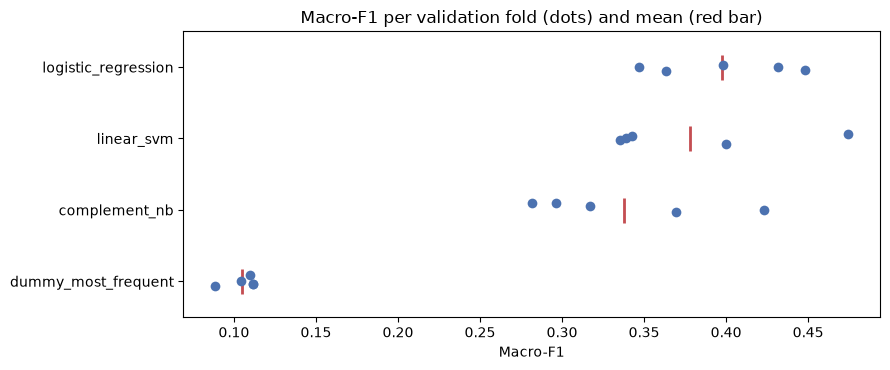

logistic_regression vs linear_svm: gap 0.019 (fold std 0.039 and 0.054)
linear_svm vs complement_nb: gap 0.041 (fold std 0.054 and 0.052)



,fold_0,fold_1,fold_2,fold_3,fold_4
model,,,,,
logistic_regression,0.431,0.363,0.448,0.347,0.398
linear_svm,0.400,0.342,0.475,0.336,0.339
complement_nb,0.369,0.296,0.423,0.282,0.317
dummy_most_frequent,0.089,0.112,0.112,0.110,0.104


In [12]:
fold_scores = (
    initial_results[["model", "fold_scores"]]
    .explode("fold_scores")
    .astype({"fold_scores": float})
    .rename(columns={"fold_scores": "macro_f1"})
)
order = initial_results.sort_values("macro_f1_mean", ascending=False)["model"]

fig, ax = plt.subplots(figsize=(9, 3.8))
sns.stripplot(data=fold_scores, x="macro_f1", y="model", order=order, size=7, color="#4C72B0", ax=ax)
sns.pointplot(data=fold_scores, x="macro_f1", y="model", order=order, color="#C44E52",
              errorbar=None, markers="|", markersize=18, linestyle="none", ax=ax)
ax.set_title("Macro-F1 per validation fold (dots) and mean (red bar)")
ax.set_xlabel("Macro-F1")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

non_dummy = initial_results.query("model != 'dummy_most_frequent'").sort_values("macro_f1_mean", ascending=False)
for first, second in zip(non_dummy.itertuples(), non_dummy.iloc[1:].itertuples()):
    print(f"{first.model} vs {second.model}: gap {first.macro_f1_mean - second.macro_f1_mean:.3f} "
          f"(fold std {first.macro_f1_std:.3f} and {second.macro_f1_std:.3f})")
print()
FOLD_COLUMNS = [f"fold_{fold}" for fold in range(N_FOLDS)]
pd.DataFrame(np.vstack(initial_results["fold_scores"]), index=initial_results["model"], columns=FOLD_COLUMNS).loc[order].round(3)

**Interpretation.** The fold scores overlap widely: logistic regression goes from 0.347 to 0.448, the linear SVM
from 0.336 to 0.475 and ComplementNB from 0.282 to 0.423. Folds 1 and 3 are among the hardest for every model and fold 2
is the easiest for all three, so much of the variation comes from which episodes are being validated, not from the model. The gap
between logistic regression and the SVM (0.019) is smaller than either standard deviation (0.039 and 0.054), so
there is no evidence that one is better than the other, even though logistic regression is ahead in 4 of the 5
folds. ComplementNB is below the SVM in all five folds. The decision of which models move on to tuning is taken at
the end of Section 7, because the comparison of feature variants could change this ranking.

## 7. Comparison of Feature Variants (Ablation Study)

**Motivation.** Notebook 02 left six ways of preparing the text, each one changing a single element of the
`baseline` preparation, and listed the questions they answer. Comparing them shows which parts of the preparation
actually help, and it has to happen before tuning, because the best settings of a model depend on the input it
receives.

| Variant | What changes with respect to `baseline` | Question it answers |
|---|---|---|
| `masked_names` | Names of the five characters replaced by `NAME` | Does the model recognize the voice, or who is being addressed? |
| `masked_names_and_address` | Also *grandpa*, *dad*, *mom*, *sweetie*... replaced | Same question, removing the kinship words that also reveal the listener |
| `unigrams_only` | Single words only, no two-word expressions | Are expressions such as *oh geez* worth about 8,600 extra columns? |
| `text_only` | Without the three numeric features (length, `?` and `!` ratios) | Do length and punctuation add anything beyond the words? |
| `raw_text` | TF-IDF on the raw dialogue, without cleaning | Does the cleaning of notebook 02 help, or does it remove useful signal? |

Each variant is evaluated with the three candidate models and the same five folds (the Dummy is left out because it
ignores the input). Every step that learns (vocabulary, IDF weights, scaler, name list) is fitted inside each fold.

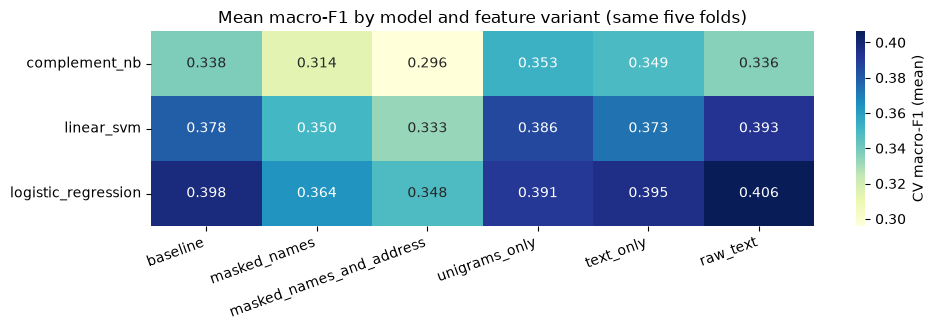

In [13]:
ABLATION_MODELS = [name for name in CANDIDATES if name != "dummy_most_frequent"]

ablation_results = pd.concat([
    initial_results.query("model in @ABLATION_MODELS"),  # baseline variant, already evaluated in Section 6
    pd.DataFrame([
        evaluate_cv(model_name, build_candidate(model_name, feature_variant=variant), "initial", variant)
        for variant in FEATURE_VARIANTS if variant != "baseline"
        for model_name in ABLATION_MODELS
    ]),
], ignore_index=True)

f1_by_variant = ablation_results.pivot(index="model", columns="feature_variant", values="macro_f1_mean")[list(FEATURE_VARIANTS)]

fig, ax = plt.subplots(figsize=(10, 3.4))
sns.heatmap(f1_by_variant, annot=True, fmt=".3f", cmap="YlGnBu", cbar_kws={"label": "CV macro-F1 (mean)"}, ax=ax)
ax.set_title("Mean macro-F1 by model and feature variant (same five folds)")
ax.set_xlabel("")
ax.set_ylabel("")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

**Interpretation.** Two patterns appear.

- **Masking always hurts, for the three models.** Replacing the five names lowers macro-F1 by 0.024 to 0.034, and
  also replacing the kinship words lowers it by 0.042 to 0.049 (logistic regression goes from 0.398 to 0.364 and
  then to 0.348). Because the drop is consistent across models, it is real: who is being addressed is a strong clue
  to who is speaking (Rick calls Morty by his name, Morty says *Rick* or *Grandpa*). The models therefore use part
  of the conversational context, not only the voice. Even without those words logistic regression keeps 0.348,
  more than three times the Dummy, so there is also a signal of voice.
- **The other three variants stay close to `baseline` and the models do not agree on their direction.** The raw
  text changes the score by +0.009 (logistic regression), +0.015 (SVM) and -0.002 (Naive Bayes); single words by
  -0.007, +0.008 and +0.015; removing the numeric features by -0.002, -0.005 and +0.011. Changes of about 0.01
  against a variation between folds of 0.04 to 0.05 cannot be told apart from noise: the cleaning, the two-word
  expressions and the three numeric features do not show a measurable effect on the score.

**Choosing the variant.** Six variants with three models each are 18 comparisons, so some differences will appear
by chance. The same **one standard error rule** used later for the final selection is applied here: for each variant
its best model is taken, and every variant whose score is within one standard error of the best variant (standard
deviation across folds divided by the square root of the number of folds) is considered tied. Among tied variants
the `baseline` of notebook 02 is kept, because a change to the preparation has to show an advantage larger than the
noise to be adopted; if `baseline` is not tied, the tied variant with the fewest columns is chosen.

In [14]:
best_per_variant = (
    ablation_results.sort_values("macro_f1_mean", ascending=False)
    .groupby("feature_variant").head(1).set_index("feature_variant")
)
# Output columns of each variant, measured on train only (structure, not performance).
n_columns = {
    variant: build_preparation_pipeline(variant).fit_transform(X_train, y_train).shape[1] for variant in FEATURE_VARIANTS
}
variant_summary = pd.DataFrame({
    "best_model": best_per_variant["model"],
    "best_macro_f1": best_per_variant["macro_f1_mean"],
    "best_macro_f1_std": best_per_variant["macro_f1_std"],
    "mean_over_models": ablation_results.groupby("feature_variant")["macro_f1_mean"].mean(),
    "columns": pd.Series(n_columns),
}).loc[list(FEATURE_VARIANTS)]
variant_summary["change_vs_baseline"] = variant_summary["best_macro_f1"] - variant_summary.loc["baseline", "best_macro_f1"]

top_variant = variant_summary["best_macro_f1"].idxmax()
variant_threshold = (
    variant_summary.loc[top_variant, "best_macro_f1"]
    - variant_summary.loc[top_variant, "best_macro_f1_std"] / np.sqrt(N_FOLDS)
)
variant_summary["within_one_se"] = variant_summary["best_macro_f1"] >= variant_threshold

# Among tied variants keep the reference of notebook 02; otherwise the one with the fewest columns.
tied_variants = variant_summary.query("within_one_se")
selected_feature_variant = "baseline" if "baseline" in tied_variants.index else tied_variants["columns"].idxmin()

print(f"Best variant: {top_variant} (macro-F1 = {variant_summary.loc[top_variant, 'best_macro_f1']:.3f}); "
      f"one-standard-error threshold: {variant_threshold:.3f}")
print(f"Selected feature variant: {selected_feature_variant}")
variant_summary.round(3)

Best variant: raw_text (macro-F1 = 0.406); one-standard-error threshold: 0.388
Selected feature variant: baseline


,best_model,best_macro_f1,best_macro_f1_std,mean_over_models,columns,change_vs_baseline,within_one_se
baseline,logistic_regression,0.398,0.039,0.371,11490,0.000,True
masked_names,logistic_regression,0.364,0.051,0.343,11371,-0.034,False
masked_names_and_address,logistic_regression,0.348,0.050,0.326,11291,-0.049,False
unigrams_only,logistic_regression,0.391,0.039,0.377,2899,-0.007,True
text_only,logistic_regression,0.395,0.038,0.372,11487,-0.002,True
raw_text,logistic_regression,0.406,0.040,0.378,12361,0.009,True


**Interpretation.** The highest score belongs to `raw_text` (0.406 with logistic regression), and the threshold is
0.388. `baseline` (0.398), `text_only` (0.395) and `unigrams_only` (0.391) are within it, so the four variants are
tied; the two masked variants (0.364 and 0.348) fall below it, so their loss is larger than the noise. Following the
rule, **`baseline` is kept**. Adopting `raw_text` is not justified: its advantage (0.009) is less than a quarter of
its variation between folds, and the raw text keeps the narration, whose density depends on each episode's
transcriber (0% to 72% in the EDA), so any gain would come from the transcriber's style rather than from the
character. `unigrams_only` would be a reasonable lighter option (2,899 columns instead of 11,490, and faster to
fit), but with fits under one second that saving does not change anything here. The masked variants are not
adopted either: they answer the question "voice or context?" (part of the signal is context), and that answer is
recorded as a limitation in the conclusions.

In [15]:
selected_variant_results = (
    ablation_results.query("feature_variant == @selected_feature_variant")
    .sort_values("macro_f1_mean", ascending=False)
)
models_to_tune = selected_variant_results["model"].head(N_MODELS_TO_TUNE).tolist()
print(f"Initial models on the selected variant ({selected_feature_variant}):")
print(selected_variant_results[["model", "macro_f1_mean", "macro_f1_std", "fit_time_s"]].round(3).to_string(index=False))
print(f"Models passed to tuning: {models_to_tune}")

Initial models on the selected variant (baseline):
              model  macro_f1_mean  macro_f1_std  fit_time_s
logistic_regression          0.398         0.039       0.554
         linear_svm          0.378         0.054       0.297
      complement_nb          0.338         0.052       0.132
Models passed to tuning: ['logistic_regression', 'linear_svm']


**Interpretation.** On `baseline`, logistic regression and the linear SVM move on to tuning. ComplementNB is left out
because it was below both in every fold. Logistic regression and the SVM cannot be separated with the initial
configuration (gap 0.019, smaller than their variation between folds), and they react to different settings, so
tuning both lets the evidence decide. Their low cost (roughly 5 s and 2 s per trial of five folds) makes 40 trials
each affordable.

## 8. Hyperparameter Optimization with Optuna

**Motivation.** Hyperparameters are settings chosen before training (for example, how strongly the model is
regularized). Optuna tries combinations and learns from the previous trials which regions of the search space look
better (TPE sampler). Each **trial** is one combination, scored by the mean macro-F1 of the same five folds; the
**study** is the history of all trials.

| Element | Decision |
|---|---|
| Objective and direction | Mean cross-validated macro-F1 on train; **maximize**. |
| Models tuned | The two best initial models on the feature variant selected in Section 7. |
| Model search space | Logistic regression: `C` from 0.01 to 100 (log scale) and `class_weight` (none or balanced). Linear SVM: `C` from 0.001 to 10 (log scale) and `class_weight`. Naive Bayes, if selected: `alpha` from 0.001 to 10 (log scale) and `norm`. |
| Text search space | TF-IDF `min_df` (1, 2 or 3) and `sublinear_tf` (whether a word repeated in a line counts with its logarithm). The vectorizer is still fitted inside each fold. |
| Not tuned | The n-gram range and the masking of names: they define the representation and belong to the comparison of feature variants, not to the model's settings. |
| Budget | 40 trials per model or 15 minutes per study, whichever comes first. |
| Reproducibility | `TPESampler` with a fixed seed per study. |

`C` controls regularization: a small `C` keeps the weights small (simpler model), a large `C` lets the model follow
the training lines more closely (risk of overfitting). The range of logistic regression covers two orders of magnitude on
each side of its default (`C=1`); the range of the SVM goes further down (0.001), because linear SVMs on many sparse
columns often need stronger regularization. Both ranges were checked to converge without warnings.

In [16]:
TFIDF_SEARCH = {"min_df": [1, 2, 3], "sublinear_tf": [False, True]}


def suggest_tfidf(trial: optuna.Trial) -> dict:
    """Text-representation options tuned together with the model; the vectorizer is still fitted inside each fold."""
    return {
        "preprocessor__text__min_df": trial.suggest_categorical("min_df", TFIDF_SEARCH["min_df"]),
        "preprocessor__text__sublinear_tf": trial.suggest_categorical("sublinear_tf", TFIDF_SEARCH["sublinear_tf"]),
    }


def suggest_model(model_name: str, trial: optuna.Trial):
    """Search space of each model, limited to the parameters that matter for linear text classifiers."""
    if model_name == "complement_nb":
        return ComplementNB(
            alpha=trial.suggest_float("alpha", 1e-3, 10.0, log=True),
            norm=trial.suggest_categorical("norm", [False, True]),
        )
    if model_name == "logistic_regression":
        return LogisticRegression(
            C=trial.suggest_float("C", 1e-2, 1e2, log=True),
            class_weight=trial.suggest_categorical("class_weight", [None, "balanced"]),
            max_iter=2_000,
        )
    if model_name == "linear_svm":
        return LinearSVC(
            C=trial.suggest_float("C", 1e-3, 1e1, log=True),
            class_weight=trial.suggest_categorical("class_weight", [None, "balanced"]),
            dual=False,
        )
    raise ValueError(f"No search space defined for {model_name}")


def build_from_params(model_name: str, params: dict) -> Pipeline:
    """Rebuild the complete pipeline of a trial (or of the best trial) on the selected feature variant."""
    trial = optuna.trial.FixedTrial(params)
    pipeline = build_candidate(model_name, suggest_model(model_name, trial), selected_feature_variant)
    return pipeline.set_params(**suggest_tfidf(trial))


def make_objective(model_name: str):
    def objective(trial: optuna.Trial) -> float:
        pipeline = build_candidate(model_name, suggest_model(model_name, trial), selected_feature_variant)
        pipeline.set_params(**suggest_tfidf(trial))
        scores = cross_validate(pipeline, X_train, y_train, cv=CV_FOLDS, scoring="f1_macro", n_jobs=N_JOBS)
        trial.set_user_attr("fold_std", float(scores["test_score"].std()))
        return float(scores["test_score"].mean())
    return objective

In [17]:
studies = {}
for study_number, model_name in enumerate(models_to_tune):
    study = optuna.create_study(
        study_name=f"{model_name}_tuned",
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE + study_number),
    )
    started = time.perf_counter()
    study.optimize(make_objective(model_name), n_trials=N_OPTUNA_TRIALS, timeout=OPTUNA_TIMEOUT_SECONDS)
    study.set_user_attr("seconds", time.perf_counter() - started)
    studies[model_name] = study

pd.DataFrame([
    {
        "model": f"{name}_tuned",
        "best_macro_f1": study.best_value,
        "best_trial": study.best_trial.number,
        "trials_completed": len(study.trials),
        "minutes": study.user_attrs["seconds"] / 60,
        **{f"best_{key}": value for key, value in study.best_params.items()},
    }
    for name, study in studies.items()
]).round(4)

,model,best_macro_f1,best_trial,trials_completed,minutes,best_C,best_class_weight,best_min_df,best_sublinear_tf
0,logistic_regression_tuned,0.4078,34,40,3.3966,0.9457,balanced,1,True
1,linear_svm_tuned,0.3987,17,40,1.1879,0.1718,balanced,1,True


**Interpretation.** Both studies completed the 40 trials well before the 15-minute limit (see the `minutes` column),
so the budget was set by the number of trials, not by time. The best logistic regression reaches 0.408 (trial 34,
`C` ≈ 0.95) and the best SVM 0.399 (trial 17, `C` ≈ 0.17). The best trial of each study uses `class_weight="balanced"`, a sign
that compensating the imbalance helps the smaller speakers, and `min_df=1`, which keeps terms seen in a single training line. Both best trials also use `sublinear_tf=True`
(repeated words counted with their logarithm), although for logistic regression several trials without it score
the same to three decimals (0.407), so that option matters little. The best `C` of logistic regression is
almost the default value (1.0), while the SVM prefers stronger regularization than its default.

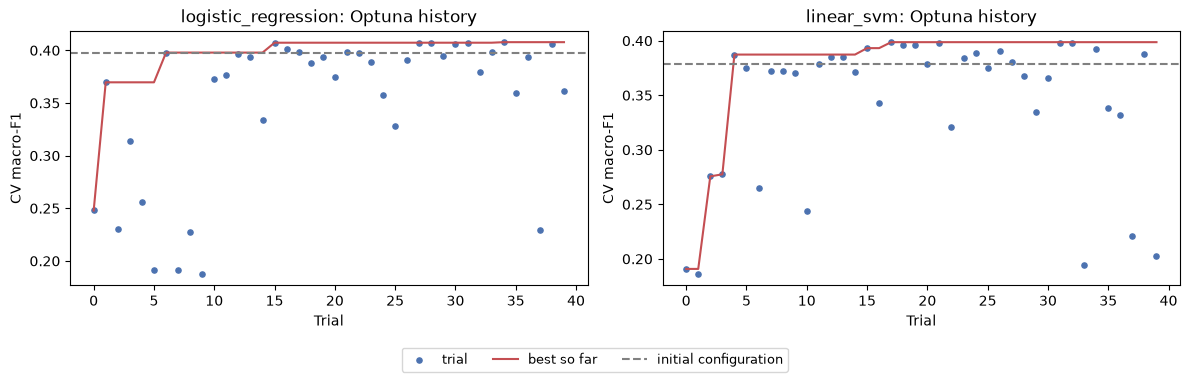

logistic_regression: median trial 0.388, worst 0.188, 12 of 40 trials above the initial configuration (0.398)
linear_svm: median trial 0.374, worst 0.186, 18 of 40 trials above the initial configuration (0.378)

Five best trials of each study:


value  params_C params_class_weight  params_min_df  params_sublinear_tf
                    number                                                                         
logistic_regression 34      0.408     0.946            balanced              1                 True
                    15      0.407     0.889            balanced              1                False
                    28      0.407     0.919            balanced              1                False
                    27      0.407     0.949            balanced              1                False
                    31      0.407     0.928            balanced              1                False
linear_svm          17      0.399     0.172            balanced              1                 True
                    32      0.398     0.154            balanced              1                 True
                    21      0.398     0.204            balanced              1                 True
                    31      0.398     0.139            balanced              1                 True
                    19      0.396     0.134            balanced              1                 True

In [18]:
fig, axes = plt.subplots(1, len(studies), figsize=(6 * len(studies), 3.8), squeeze=False)
for ax, (name, study) in zip(axes[0], studies.items()):
    values = pd.Series([t.value for t in study.trials])
    ax.scatter(values.index, values, s=14, color="#4C72B0", label="trial")
    ax.plot(values.cummax(), color="#C44E52", label="best so far")
    ax.axhline(selected_variant_results.set_index("model").loc[name, "macro_f1_mean"], color="gray", linestyle="--",
               label="initial configuration")
    ax.set_title(f"{name}: Optuna history")
    ax.set_xlabel("Trial")
    ax.set_ylabel("CV macro-F1")
handles, labels = axes[0][0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=9)  # below the panels, so no trial is hidden
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

top_trials = {}
for name, study in studies.items():
    trials = study.trials_dataframe()
    initial_score = selected_variant_results.set_index("model").loc[name, "macro_f1_mean"]
    print(f"{name}: median trial {trials['value'].median():.3f}, worst {trials['value'].min():.3f}, "
          f"{int((trials['value'] > initial_score).sum())} of {len(trials)} trials above the initial configuration "
          f"({initial_score:.3f})")
    top_trials[name] = trials.nlargest(5, "value").set_index("number")[
        ["value", *[column for column in trials.columns if column.startswith("params_")]]
    ]
print("\nFive best trials of each study:")
pd.concat(top_trials).round(3)

**Interpretation.** Most trials fall in a narrow band (median 0.388 for logistic regression and 0.374 for the SVM),
and a few score far lower (about 0.19), which shows that the search also explored poor regions. The best-so-far line
flattens early: the five best trials of logistic regression are all between 0.407 and 0.408, with `C` between 0.89
and 0.95, and the five best of the SVM between 0.396 and 0.399, with `C` between 0.13 and 0.20. Optuna has
concentrated on one region and finds no better one, so more trials are unlikely to bring a relevant gain: the budget
was sufficient. Only 12 of the 40 logistic-regression trials and 18 of the 40 SVM trials beat the initial
configuration (dashed line), another sign that the defaults were already reasonable.

**Tuned versus initial.** The best trial is re-evaluated with the same function and folds as the initial models, so
the comparison uses one protocol for everyone and includes the secondary metrics and the variation between folds.

In [19]:
tuned_results = pd.DataFrame([
    evaluate_cv(f"{name}_tuned", build_from_params(name, study.best_params), "tuned", selected_feature_variant)
    for name, study in studies.items()
])
tuned_results.insert(1, "configuration", [str(study.best_params) for study in studies.values()])

before_after = pd.concat([
    selected_variant_results[selected_variant_results["model"].isin(models_to_tune)],
    tuned_results,
])
print("Macro-F1 per fold, initial and tuned:")
print(pd.DataFrame(np.vstack(before_after["fold_scores"]), index=before_after["model"], columns=FOLD_COLUMNS)
      .round(3).to_string())
before_after[comparison_columns].round(3)

Macro-F1 per fold, initial and tuned:
                           fold_0  fold_1  fold_2  fold_3  fold_4
model                                                            
logistic_regression         0.431   0.363   0.448   0.347   0.398
linear_svm                  0.400   0.342   0.475   0.336   0.339
logistic_regression_tuned   0.453   0.363   0.470   0.350   0.403
linear_svm_tuned            0.425   0.356   0.458   0.343   0.411


,model,configuration,macro_f1_mean,macro_f1_std,accuracy_mean,balanced_accuracy_mean,fit_time_s
1,logistic_regression,"C=1.0, class_weight=balanced, lbfgs (multinomial)",0.398,0.039,0.457,0.403,0.554
2,linear_svm,"C=1.0, class_weight=balanced, primal solver",0.378,0.054,0.454,0.381,0.297
0,logistic_regression_tuned,"{'C': 0.9456936678424016, 'class_weight': 'balanced', 'min_df': 1, 'sublinea...",0.408,0.047,0.470,0.413,1.081
1,linear_svm_tuned,"{'C': 0.1718369316725967, 'class_weight': 'balanced', 'min_df': 1, 'sublinea...",0.399,0.043,0.477,0.401,0.329


**Interpretation.** Tuning improves logistic regression from 0.398 to 0.408 (+0.010) and the SVM from 0.378 to
0.399 (+0.021), and accuracy also rises (0.457 to 0.470 and 0.454 to 0.477). Both gains are consistent, since each
tuned model beats its initial version in 4 of the 5 folds, but they are smaller than the variation between folds
(0.039 to 0.054), so **the tuning produced a small, not a relevant, improvement**. The tuned scores are also slightly
optimistic, because each one is the best of 40 attempts measured on the same folds. Tuning had a cost for logistic
regression: with `min_df=1` the vocabulary is larger and its fitting time roughly doubles (from about 0.6 s to more than
1 s per fold), while the SVM stays under half a second.

## 9. Selection with Cross-Validation Only

**Motivation.** The final pipeline is chosen among all initial and tuned candidates using only cross-validation.
Choosing the highest mean blindly would reward differences smaller than the noise between folds, so the **one
standard error rule** is applied: every pipeline whose mean macro-F1 is within one standard error of the best one
(standard error = standard deviation of the best one divided by the square root of the number of folds) is
considered tied, and among the tied pipelines the cheapest to fit is chosen. Test is not used.

In [20]:
candidates_for_selection = pd.concat([selected_variant_results, tuned_results], ignore_index=True)

best = candidates_for_selection.loc[candidates_for_selection["macro_f1_mean"].idxmax()]
standard_error = best["macro_f1_std"] / np.sqrt(N_FOLDS)
threshold = best["macro_f1_mean"] - standard_error
candidates_for_selection["within_one_se"] = candidates_for_selection["macro_f1_mean"] >= threshold

# Among the statistically tied pipelines, prefer the cheapest one to fit.
eligible = candidates_for_selection.query("within_one_se").sort_values("fit_time_s")
selected = eligible.iloc[0]
SELECTED_MODEL = selected["model"]

print(f"Best mean: {best['model']} (macro-F1 = {best['macro_f1_mean']:.3f} ± {best['macro_f1_std']:.3f})")
print(f"One-standard-error threshold: {threshold:.3f}")
print(f"Selected pipeline: {SELECTED_MODEL} on {selected_feature_variant} (macro-F1 = {selected['macro_f1_mean']:.3f} ± "
      f"{selected['macro_f1_std']:.3f}, fit time {selected['fit_time_s']:.2f} s)")
candidates_for_selection.sort_values("macro_f1_mean", ascending=False)[
    ["model", "stage", "macro_f1_mean", "macro_f1_std", "fit_time_s", "within_one_se"]
].round(3)

Best mean: logistic_regression_tuned (macro-F1 = 0.408 ± 0.047)
One-standard-error threshold: 0.387
Selected pipeline: linear_svm_tuned on baseline (macro-F1 = 0.399 ± 0.043, fit time 0.33 s)


,model,stage,macro_f1_mean,macro_f1_std,fit_time_s,within_one_se
3,logistic_regression_tuned,tuned,0.408,0.047,1.081,True
4,linear_svm_tuned,tuned,0.399,0.043,0.329,True
0,logistic_regression,initial,0.398,0.039,0.554,True
1,linear_svm,initial,0.378,0.054,0.297,False
2,complement_nb,initial,0.338,0.052,0.132,False


**Interpretation.** The best mean is the tuned logistic regression (0.408 ± 0.047), so the standard error is
0.047 / √5 ≈ 0.021 and the threshold 0.387. Three pipelines are tied: the tuned logistic regression, the tuned SVM
(0.399) and the initial logistic regression (0.398); the initial SVM and ComplementNB fall below. Among the tied ones
the cheapest to fit is the **tuned linear SVM** (under half a second per fold, against about 0.6 s and more than 1 s), which is selected. It
is preferred to the tuned logistic regression because their difference (0.009) is less than half a standard error,
its variation between folds is similar (0.043 against 0.047), and it fits several times faster. It does not
give probabilities, but the task only needs the predicted speaker. Test has not been used in any of these
decisions.

In [21]:
base_name = SELECTED_MODEL.removesuffix("_tuned")
if SELECTED_MODEL.endswith("_tuned"):
    final_pipeline = build_from_params(base_name, studies[base_name].best_params)
else:
    final_pipeline = build_candidate(base_name, feature_variant=selected_feature_variant)

print(f"Selected pipeline: {SELECTED_MODEL}, feature variant {selected_feature_variant}")
for step_name, step in final_pipeline.steps:
    print(f"  {step_name:<15} {type(step).__name__}")
print(f"  model parameters: {final_pipeline.named_steps['model'].get_params()}")
text_step = final_pipeline.named_steps["preprocessor"].transformers[0][1]
print(f"  TF-IDF: ngram_range={text_step.ngram_range}, min_df={text_step.min_df}, sublinear_tf={text_step.sublinear_tf}")

Selected pipeline: linear_svm_tuned, feature variant baseline
  text_features   FunctionTransformer
  name_masking    CharacterNameMasker
  preprocessor    ColumnTransformer
  model           LinearSVC
  model parameters: {'C': 0.1718369316725967, 'class_weight': 'balanced', 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'loss': 'squared_hinge', 'max_iter': 1000, 'multi_class': 'ovr', 'penalty': 'l2', 'random_state': None, 'tol': 0.0001, 'verbose': 0}
  TF-IDF: ngram_range=(1, 2), min_df=1, sublinear_tf=True


## 10. Error Analysis on Train (Out-of-Fold)

**Motivation.** Before looking at test, the errors of the selected pipeline are studied with out-of-fold predictions:
every training line is predicted by the model of the fold in which it was a validation line, so no prediction comes
from a model that saw that line. This shows which speakers are confused and where the model fails, without
consulting test.

In [22]:
oof_pred = cross_val_predict(clone(final_pipeline), X_train, y_train, cv=CV_FOLDS, n_jobs=N_JOBS)

oof_report = pd.DataFrame(
    classification_report(y_train, oof_pred, labels=TOP_SPEAKERS, output_dict=True, zero_division=0)
).T.loc[TOP_SPEAKERS, ["precision", "recall", "f1-score", "support"]]
print(f"Out-of-fold macro-F1 on train: {f1_score(y_train, oof_pred, average='macro'):.3f}")
oof_report["predicted"] = pd.Series(oof_pred).value_counts().reindex(TOP_SPEAKERS, fill_value=0)
oof_report.round(3)

Out-of-fold macro-F1 on train: 0.400


,precision,recall,f1-score,support,predicted
Rick,0.583,0.664,0.620,1700.0,1936
Morty,0.529,0.538,0.533,1239.0,1262
Jerry,0.325,0.259,0.288,710.0,567
Beth,0.306,0.272,0.288,574.0,509
Summer,0.287,0.258,0.272,515.0,464


**Interpretation.** The out-of-fold macro-F1 (0.400) matches the cross-validated mean (0.399), as it should, since
every line is predicted by a model that did not see it. The two protagonists are recognized much better (F1 of 0.62
for Rick and 0.53 for Morty) than Jerry, Beth and Summer (0.27 to 0.29). Rick's recall (0.66) is higher than his
precision (0.58): the model predicts Rick for 1,936 lines when he says 1,700, so it over-predicts him even with
balanced class weights. These out-of-fold scores share the slight optimism of the tuned scores, because the
hyperparameters were chosen on the same folds.

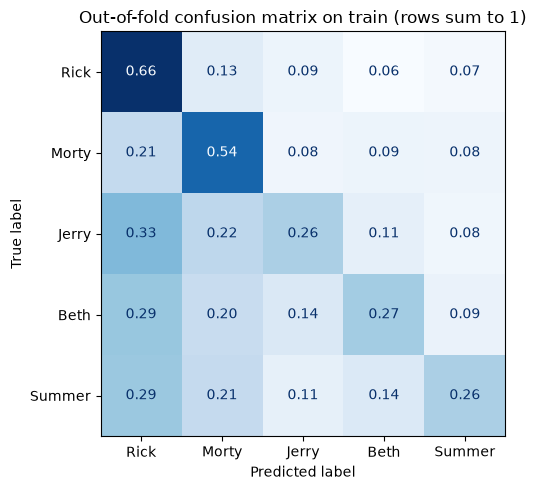

Most frequent confusions (true -> predicted, lines):
Morty  Rick     260
Jerry  Rick     233
Rick   Morty    215
Beth   Rick     167
Jerry  Morty    159


In [23]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_train, oof_pred, labels=TOP_SPEAKERS, normalize="true", values_format=".2f", cmap="Blues", colorbar=False, ax=ax
)
ax.set_title("Out-of-fold confusion matrix on train (rows sum to 1)")
plt.tight_layout()
plt.show()

oof_confusion = pd.DataFrame(confusion_matrix(y_train, oof_pred, labels=TOP_SPEAKERS), index=TOP_SPEAKERS, columns=TOP_SPEAKERS)
off_diagonal = oof_confusion.where(~np.eye(len(TOP_SPEAKERS), dtype=bool)).stack().sort_values(ascending=False)
print("Most frequent confusions (true -> predicted, lines):")
print(off_diagonal.head(5).astype(int).to_string())

**Interpretation.** The dominant error is answering Rick: about a third of Jerry's lines (33%) and 29% of Beth's and
Summer's are attributed to him, and 21% of Morty's. The second destination is Morty, who receives 20% to 22% of the
lines of Beth, Jerry and Summer. The three secondary characters are confused more with the two protagonists than
with each other (Beth's lines go to Jerry 14% of the time, Jerry's to Beth 11%). The largest counts are Morty → Rick
(260 lines), Jerry → Rick (233) and Rick → Morty (215). When a line carries no clear signal, the model falls back on
the two characters with the most lines and the most distinctive vocabulary.

In [24]:
errors = (
    add_text_features(X_train)[["dialogue_clean"]]
    .assign(true=y_train.values, predicted=oof_pred, n_words=lambda d: d["dialogue_clean"].str.split().str.len())
)
errors["correct"] = errors["true"].eq(errors["predicted"])
length_bins = pd.cut(errors["n_words"], bins=[0, 2, 5, 10, 20, np.inf], labels=["1-2", "3-5", "6-10", "11-20", "21+"])
print("Out-of-fold accuracy by line length (words):")
print(errors.groupby(length_bins, observed=True)["correct"].agg(["mean", "size"]).round(3).to_string())
print()
top_pair = off_diagonal.index[0]
errors.query("true == @top_pair[0] and predicted == @top_pair[1]").sample(6, random_state=RANDOM_STATE)[
    ["dialogue_clean", "true", "predicted"]
]

Out-of-fold accuracy by line length (words):
          mean  size
n_words             
1-2      0.401   741
3-5      0.383   916
6-10     0.414  1107
11-20    0.538  1147
21+      0.659   827



,dialogue_clean,true,predicted
2081,Why don't we just make the solar system with eight planets? It's even easier!,Morty,Rick
7155,Return the Truth Tortoise!,Morty,Rick
8346,Jesus Fucking Chist enough already!,Morty,Rick
7190,What did he say?,Morty,Rick
7739,"Uh, that's flattering... and a little weird.",Morty,Rick
9397,So did you help build the Citadel? Did you just lie to me about everything?,Morty,Rick


**Interpretation.** Accuracy grows with the length of the line: 0.40 for one or two words, 0.38 for three to five,
0.41 for six to ten, 0.54 for eleven to twenty and 0.66 above twenty. Lines of five words or fewer are 35% of the
training data (1,657 of 4,738), and on them the model is barely above the 0.359 that always answering Rick obtains on the whole training set, so short
lines
are the main limit of the task. The examples of Morty's lines predicted as Rick show why: some contain nothing
characteristic of anyone (*"What did he say?"*, *"Return the Truth Tortoise!"*), and others are questions addressed
to Rick that a viewer recognizes from the scene (*"Did you just lie to me about everything?"*), which a model that
reads one line at a time cannot see. These errors come from the information available in a single line more than
from the choice of model.

## 11. Final Fit and Single Evaluation on Test

**Motivation.** All decisions are now closed: preparation, model and hyperparameters. The selected pipeline is fitted
on all of train and test is used **once** to estimate how it generalizes to episodes it has never seen. The result is
reported as it is; it is not used to go back and change any decision.

In [25]:
final_pipeline.fit(X_train, y_train)
y_pred = final_pipeline.predict(X_test)

test_metrics = pd.DataFrame([{
    "pipeline": SELECTED_MODEL,
    "feature_variant": selected_feature_variant,
    "macro_f1": f1_score(y_test, y_pred, average="macro"),
    "accuracy": accuracy_score(y_test, y_pred),
    "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
    "cv_macro_f1_mean": selected["macro_f1_mean"],
    "cv_macro_f1_std": selected["macro_f1_std"],
}]).round(3)
test_metrics

,pipeline,feature_variant,macro_f1,accuracy,balanced_accuracy,cv_macro_f1_mean,cv_macro_f1_std
0,linear_svm_tuned,baseline,0.36,0.419,0.359,0.399,0.043


**Interpretation.** On the 1,117 lines of the 8 test episodes the selected pipeline reaches a macro-F1 of **0.360**,
an accuracy of 0.419 and a balanced accuracy of 0.359. The macro-F1 is 0.039 below the cross-validated mean
(0.399 ± 0.043): a drop of about one standard deviation, inside the range of the validation folds (0.343 to 0.458).
The test result is therefore consistent with cross-validation, at its lower end, and it shows that a result on 8
episodes depends on which episodes were drawn. The model still clearly beats the naive reference: always answering
Rick would give an accuracy of 0.347 on these lines (388 of 1,117) and a macro-F1 of about 0.10. This number is
reported as it is and is not used to change any decision.

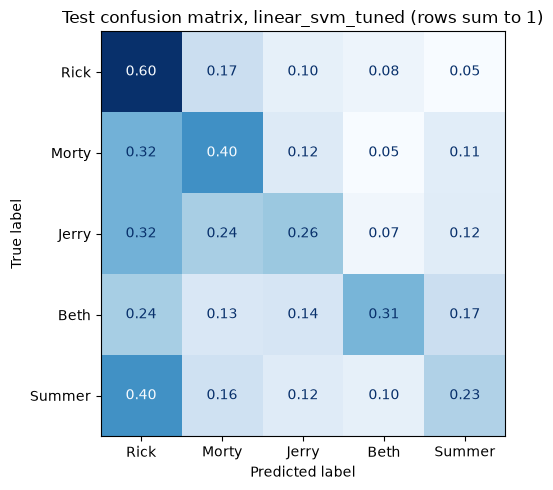

,precision,recall,f1-score,support
Rick,0.499,0.601,0.545,388.0
Morty,0.481,0.397,0.435,325.0
Jerry,0.231,0.262,0.245,130.0
Beth,0.343,0.308,0.325,120.0
Summer,0.276,0.227,0.249,154.0
macro avg,0.366,0.359,0.360,1117.0


In [26]:
test_report = pd.DataFrame(
    classification_report(y_test, y_pred, labels=TOP_SPEAKERS, output_dict=True, zero_division=0)
).T.loc[TOP_SPEAKERS + ["macro avg"], ["precision", "recall", "f1-score", "support"]]

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=TOP_SPEAKERS, normalize="true", values_format=".2f", cmap="Blues", colorbar=False, ax=ax
)
ax.set_title(f"Test confusion matrix, {SELECTED_MODEL} (rows sum to 1)")
plt.tight_layout()
plt.show()
test_report.round(3)

**Interpretation.** The pattern of errors is the same as in the out-of-fold analysis, which suggests that it is a
property of the task and not of the training folds. Rick is recognized best (F1 0.545, recall 0.60) and Morty second
(0.435); Beth (0.325), Summer (0.249) and Jerry (0.245) remain hard. The main error is again answering Rick: 40% of
Summer's lines, 32% of Morty's and of Jerry's and 24% of Beth's go to him. Jerry and Summer are the weakest classes on test
(F1 0.245 and 0.249), and Summer weighs more here than in training (154 lines, 13.8% of test against 10.9% of
train), which can explain part of the drop of macro-F1 with respect to cross-validation. Morty's recall falls from 0.54 out-of-fold to 0.40 on test,
mostly towards Rick.

In [27]:
assert len(y_pred) == len(X_test)
assert set(y_pred) <= set(TOP_SPEAKERS)
assert not (set(X_train[GROUP_COLUMN]) & set(X_test[GROUP_COLUMN]))
assert final_pipeline.named_steps["model"].__class__ is build_candidate(base_name).named_steps["model"].__class__
variant = FEATURE_VARIANTS[selected_feature_variant]
masker = final_pipeline.named_steps["name_masking"]
assert (masker.mask_names, masker.mask_address_terms) == (variant["mask_names"], variant["mask_address_terms"])
assert final_pipeline.named_steps["preprocessor"].transformers[0][2] == variant["text_column"]
print("Final checks passed: the fitted pipeline is the selected model on the selected feature variant.")

Final checks passed: the fitted pipeline is the selected model on the selected feature variant.


## 12. Conclusions

**Which pipeline was selected?** The notebook 02 preparation with its `baseline` feature variant (cleaned text,
TF-IDF of words and two-word expressions with `min_df=1` and `sublinear_tf=True`, plus the three scaled numeric
features, names kept) followed by a **linear SVM** (`LinearSVC`, `C` ≈ 0.17, `class_weight="balanced"`).

**What was its mean performance and variation?** Macro-F1 of 0.399 ± 0.043 in the five episode-grouped folds, about
four times the Dummy (0.105). On the single evaluation on test it reached 0.360 (accuracy 0.419), within one
standard deviation of the validation estimate.

**Did tuning produce a relevant improvement?** No. Optuna (40 trials per model, cross-validated inside each trial)
raised the SVM from 0.378 to 0.399 and logistic regression from 0.398 to 0.408. The gains are consistent across folds
but smaller than the variation between folds, and the best trials form a flat plateau, so the default settings were
already close to the best available ones for these models.

**Why is it preferred to similar alternatives?** The tuned logistic regression, the tuned SVM and the initial
logistic regression are statistically tied under the one-standard-error rule. The SVM is the cheapest of the three to
fit, with similar stability. Among the feature variants, `baseline` was kept because no alternative beat it by more
than the noise; `raw_text` scored 0.009 more but would rely on narration written by each transcriber.

**What was learned about the data.** Hiding the names and kinship words lowers every model by 0.024 to 0.049, more
than the noise: part of what the model uses is who is being addressed, not only how the character speaks. The
cleaning, the two-word expressions and the numeric features do not change the score measurably. The errors
concentrate on short lines (accuracy 0.40 for lines of one or two words, 0.66 for lines over twenty) and on Jerry,
Beth and Summer, who are mostly confused with Rick.

**Limitations that remain.**
- A single line is often not enough to identify the speaker: many short lines (*"What did he say?"*) could be said
  by anyone, and a model that reads one line at a time cannot use the scene.
- The model leans on Rick: it predicts him more often than he speaks and is the main source of error for the other
  four characters.
- Part of its signal is conversational context (names and terms of address), so it partly recognizes who is being
  talked to rather than the voice.
- Test contains only 8 episodes, so its result depends on the draw; the EDA also saw the whole dataset, so test is
  not a perfectly untouched final set.
- Only the five main characters are predicted; transformed versions such as *Pickle Rick* and all other speakers
  are outside the task.

**What could be explored with more time.** The alternative targets of notebook 02 (top-5 or top-10 + `"Other"`),
models that read the previous lines of the scene (a different question from the single-line premise, to be reported
separately), a comparison with a random, non-grouped cross-validation to measure how optimistic it would be, and text
representations that capture meaning beyond exact words, such as pretrained sentence embeddings.